### Question 2 

### Question 2A : Preprocessing

In [1]:
import pandas as pd
from kafka import KafkaProducer, KafkaConsumer
from collections import defaultdict
import json
print("Libraries imported successfully.")

Libraries imported successfully.


In [3]:
def extract(file_path):
    df = pd.read_excel(file_path)
    return df

print("Extract function created.")

file_path = "Online Retail.xlsx"

df = extract(file_path)

print("Dataset loaded successfully.")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Extract function created.
Dataset loaded successfully.
Rows: 541909
Columns: 8


In [4]:
print("Column Names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
print(df.head())

Column Names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

First 5 rows:
  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

          InvoiceDate  UnitPrice  CustomerID         Country  
0 2010-12-01 08:26:00       2.55     17850.0  United Kingdom  
1 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
2 2010-12-01 08:26:00       2.75     17850.0  United Kingdom  
3 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
4 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  


In [5]:
def preprocess(df):

    region_map = {

        # Europe
        "United Kingdom": "Europe",
        "EIRE": "Europe",
        "France": "Europe",
        "Germany": "Europe",
        "Netherlands": "Europe",
        "Belgium": "Europe",
        "Spain": "Europe",
        "Portugal": "Europe",
        "Italy": "Europe",
        "Switzerland": "Europe",
        "Norway": "Europe",
        "Sweden": "Europe",
        "Denmark": "Europe",
        "Finland": "Europe",
        "Austria": "Europe",
        "Poland": "Europe",
        "Cyprus": "Europe",
        "Greece": "Europe",
        "Iceland": "Europe",
        "Malta": "Europe",
        "Czech Republic": "Europe",
        "Lithuania": "Europe",

        # Asia
        "Japan": "Asia",
        "Singapore": "Asia",
        "Hong Kong": "Asia",
        "China": "Asia",

        # Americas
        "USA": "Americas",
        "Canada": "Americas",
        "Brazil": "Americas",

        # Middle East
        "Israel": "Middle_East",
        "Saudi Arabia": "Middle_East",
        "Bahrain": "Middle_East",
        "United Arab Emirates": "Middle_East",

        # Oceania
        "Australia": "Oceania"
    }

    # Create Region column
    df["Region"] = df["Country"].map(region_map)

    # Everything else becomes Other
    df["Region"] = df["Region"].fillna("Other")

    # Create regional dataframes
    EU_df = df[df["Region"] == "Europe"]
    ASIA_df = df[df["Region"] == "Asia"]
    AMERICAS_df = df[df["Region"] == "Americas"]
    ME_df = df[df["Region"] == "Middle_East"]
    OCEANIA_df = df[df["Region"] == "Oceania"]
    OTHER_df = df[df["Region"] == "Other"]

    print("Preprocessing complete.")
    print("Total columns:", len(df.columns))
    print("\nRecords per region:")
    print(df["Region"].value_counts())

    return (
        df,
        EU_df,
        ASIA_df,
        AMERICAS_df,
        ME_df,
        OCEANIA_df,
        OTHER_df
    )

In [6]:
(
    df,
    EU_df,
    ASIA_df,
    AMERICAS_df,
    ME_df,
    OCEANIA_df,
    OTHER_df
) = preprocess(df)

Preprocessing complete.
Total columns: 9

Records per region:
Region
Europe         537539
Other            1368
Oceania          1259
Asia              875
Americas          474
Middle_East       394
Name: count, dtype: int64


In [7]:
print("Europe:", EU_df.shape)
print("Asia:", ASIA_df.shape)
print("Americas:", AMERICAS_df.shape)
print("Middle_East:", ME_df.shape)
print("Oceania:", OCEANIA_df.shape)
print("Other:", OTHER_df.shape)

Europe: (537539, 9)
Asia: (875, 9)
Americas: (474, 9)
Middle_East: (394, 9)
Oceania: (1259, 9)
Other: (1368, 9)


In [8]:
EU_df.to_csv("Europe.csv", index=False)
ASIA_df.to_csv("Asia.csv", index=False)
AMERICAS_df.to_csv("Americas.csv", index=False)
ME_df.to_csv("Middle_East.csv", index=False)
OCEANIA_df.to_csv("Oceania.csv", index=False)
OTHER_df.to_csv("Other.csv", index=False)

print("All 6 regional datasets saved successfully.")

All 6 regional datasets saved successfully.


### Question 2B : Streaming 

In [11]:
producer = KafkaProducer(
    bootstrap_servers='localhost:9092',
    value_serializer=lambda x: json.dumps(x).encode('utf-8')
)

print("Producer created successfully.")

Producer created successfully.


### Regional Files 

In [12]:
files = [
    "Europe.csv",
    "Asia.csv",
    "Americas.csv",
    "Middle_East.csv",
    "Oceania.csv",
    "Other.csv"
]

print("Regional files loaded.")
print(files)

Regional files loaded.
['Europe.csv', 'Asia.csv', 'Americas.csv', 'Middle_East.csv', 'Oceania.csv', 'Other.csv']


### Producer 

In [13]:
total_sent = 0

for file in files:

    count = 0

    for record in data_generator(file):

        topic = record["Region"]

        producer.send(topic, value=record)

        count += 1
        total_sent += 1

        if count % 50000 == 0:
            print(f"{file}: {count:,} records sent")

    print(f"Finished sending {count:,} records from {file}")

producer.flush()

print(f"\nProducer finished. Total sent: {total_sent:,}")

Europe.csv: 50,000 records sent
Europe.csv: 100,000 records sent
Europe.csv: 150,000 records sent
Europe.csv: 200,000 records sent
Europe.csv: 250,000 records sent
Europe.csv: 300,000 records sent
Europe.csv: 350,000 records sent
Europe.csv: 400,000 records sent
Europe.csv: 450,000 records sent
Europe.csv: 500,000 records sent
Finished sending 537,539 records from Europe.csv
Finished sending 875 records from Asia.csv
Finished sending 474 records from Americas.csv
Finished sending 394 records from Middle_East.csv
Finished sending 1,259 records from Oceania.csv
Finished sending 1,368 records from Other.csv

Producer finished. Total sent: 541,909


### Consumer 

In [14]:
# Topics created in Question 2B
topics = [
    "Europe",
    "Asia",
    "Americas",
    "Middle_East",
    "Oceania",
    "Other"
]

print("Subscribing to:", topics)

consumer = KafkaConsumer(
    *topics,
    bootstrap_servers='localhost:9092',
    auto_offset_reset='earliest',
    enable_auto_commit=True,
    group_id='retail-consumer-group-final',
    value_deserializer=lambda m: json.loads(m.decode('utf-8')),
    consumer_timeout_ms=30000
)

# Assignment metrics
msg_count = defaultdict(int)
cumulative_sales = defaultdict(float)
unknown_customers = defaultdict(int)

for message in consumer:

    topic = message.topic
    row = message.value

    # (a) Count messages per topic
    msg_count[topic] += 1

    # (b) Calculate total sales
    try:
        qty = float(row.get("Quantity", 0) or 0)
        price = float(row.get("UnitPrice", 0) or 0)

        # (c) Maintain cumulative sales
        cumulative_sales[topic] += qty * price

    except (ValueError, TypeError):
        pass

    # (d) Count unknown purchasers
    cid = str(row.get("CustomerID", "")).strip()

    if cid in ("", "nan", "NaN", "None"):
        unknown_customers[topic] += 1

    total = sum(msg_count.values())

    if total % 50000 == 0:
        print(f"Consumed {total:,} messages...")

consumer.close()

print("\nConsumer finished.")
print(f"Total consumed: {sum(msg_count.values()):,}")

print("\nMessages per Topic")
for topic in topics:
    print(f"{topic}: {msg_count[topic]:,}")

print("\nConsumer processing complete.")

Subscribing to: ['Europe', 'Asia', 'Americas', 'Middle_East', 'Oceania', 'Other']
Consumed 50,000 messages...
Consumed 100,000 messages...
Consumed 150,000 messages...
Consumed 200,000 messages...
Consumed 250,000 messages...
Consumed 300,000 messages...
Consumed 350,000 messages...
Consumed 400,000 messages...
Consumed 450,000 messages...
Consumed 500,000 messages...

Consumer finished.
Total consumed: 541,909

Messages per Topic
Europe: 537,539
Asia: 875
Americas: 474
Middle_East: 394
Oceania: 1,259
Other: 1,368

Consumer processing complete.


### Summary table 

In [19]:
summary_df = pd.DataFrame({
    "Topic_Name": list(msg_count.keys()),
    "Messages_Consumed": [msg_count[t] for t in msg_count.keys()],
    "Total_Sales": [round(cumulative_sales[t], 2) for t in msg_count.keys()],
    "Unknown_Purchasers": [unknown_customers[t] for t in msg_count.keys()]
})

summary_df = summary_df.sort_values("Topic_Name")
display(summary_df)

print("\nQuestion 2D.5 completed successfully.")

,Topic_Name,Messages_Consumed,Total_Sales,Unknown_Purchasers
0,Americas,474,6540.90,0
1,Asia,875,54578.05,288
2,Europe,537539,9510238.02,134541
5,Middle_East,394,10489.67,49
4,Oceania,1259,137077.27,0
3,Other,1368,28824.02,202



Question 2D.5 completed successfully.


### Question 2C

In [25]:
top3_countries = (
    df.groupby("Country")
      .size()
      .sort_values(ascending=False)
      .head(3)
)

print("Top 3 countries by number of purchases:")
print(top3_countries)


Top 3 countries by number of purchases:
Country
United Kingdom    495478
Germany             9495
France              8557
dtype: int64


In [27]:
top3_sales = (
    df[df["Country"].isin(top3_countries.index)]
      .groupby("Country")["SaleValue"]
      .sum()
      .sort_values(ascending=False)
)

print("Total sales for the Top 3 Countries:")
print(top3_sales)

Total sales for the Top 3 Countries:
Country
United Kingdom    8187806.364
Germany            221698.210
France             197403.900
Name: SaleValue, dtype: float64


In [22]:
top_stock_per_region = (
    df.groupby(["Region", "Description"])["Quantity"]
      .sum()
      .reset_index()
)

top_stock_per_region = (
    top_stock_per_region.loc[
        top_stock_per_region.groupby("Region")["Quantity"].idxmax()
    ]
)

print("Most sold stock item per region:")
display(top_stock_per_region)

Most sold stock item per region:


,Region,Description,Quantity
210,Americas,RETRO COFFEE MUGS ASSORTED,504
658,Asia,RABBIT NIGHT LIGHT,3401
4846,Europe,WORLD WAR 2 GLIDERS ASSTD DESIGNS,52742
5380,Middle_East,WOODLAND CHARLOTTE BAG,130
5677,Oceania,MINI PAINT SET VINTAGE,2916
6485,Other,RAIN PONCHO,407


### Question 2D

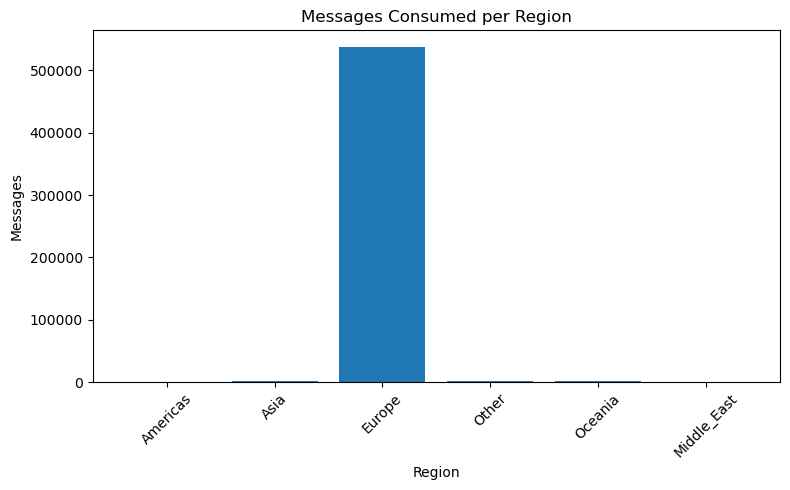

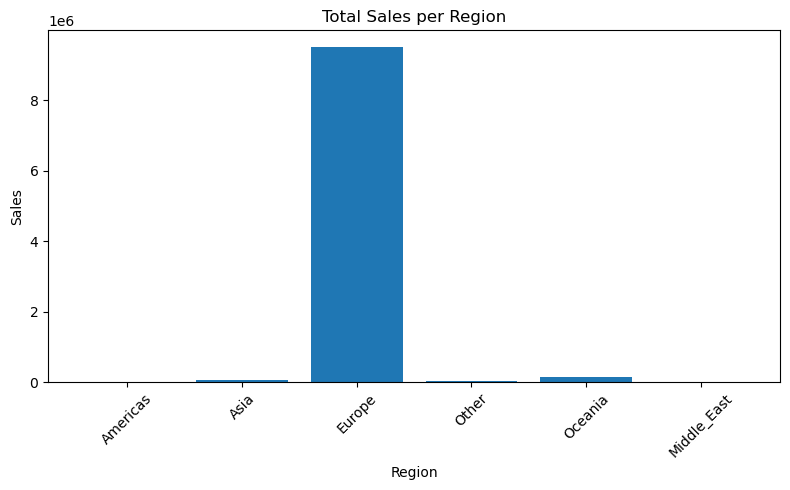

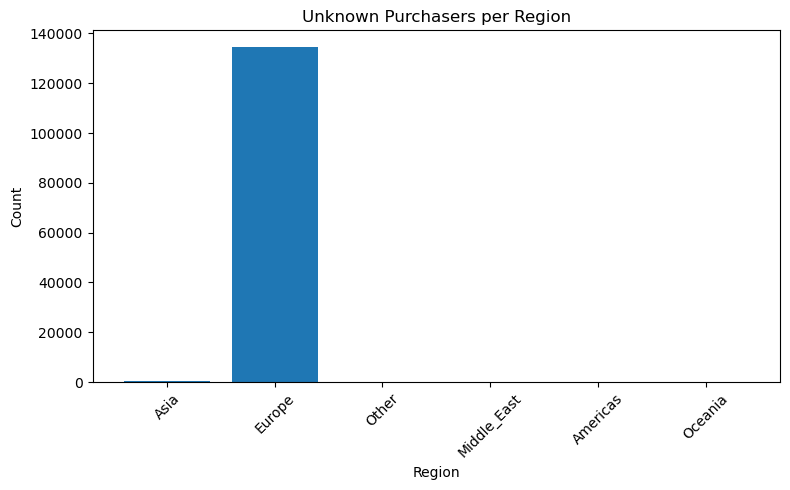

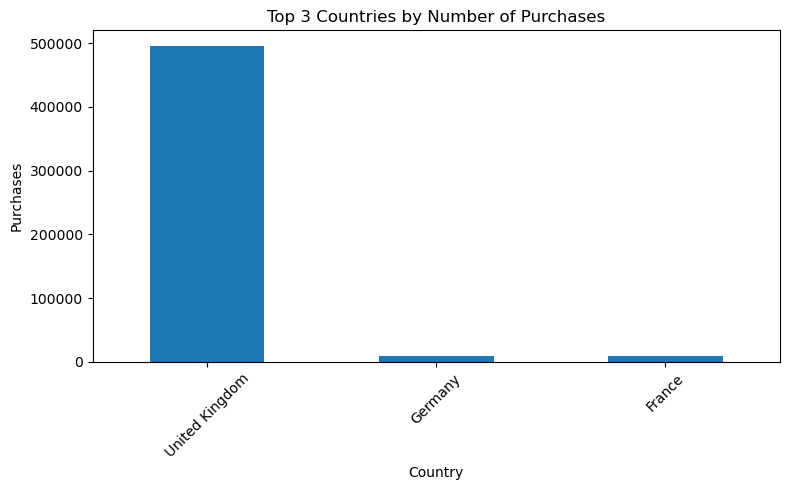

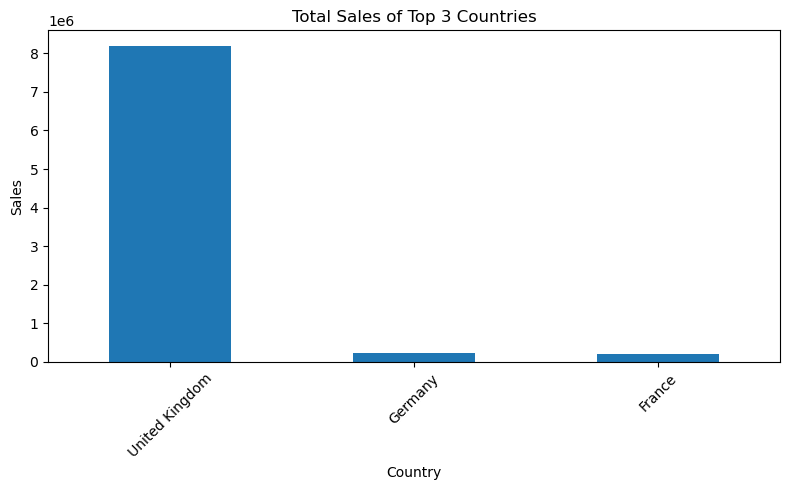

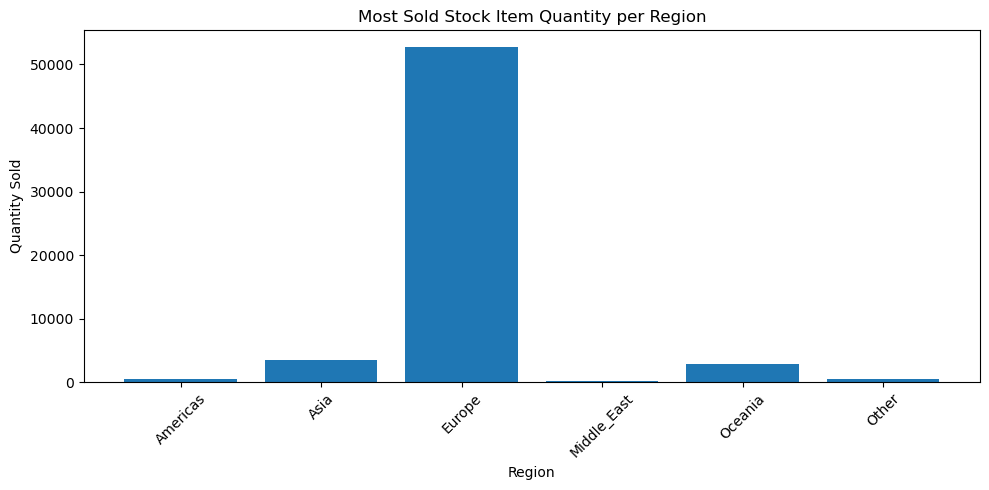

Question 2D completed successfully.


In [32]:
import matplotlib.pyplot as plt

# =========================
# 2B.5a Messages per Region
# =========================
plt.figure(figsize=(8,5))
plt.bar(msg_count.keys(), msg_count.values())
plt.title("Messages Consumed per Region")
plt.xlabel("Region")
plt.ylabel("Messages")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# =========================
# 2B.5b Total Sales per Region
# =========================
plt.figure(figsize=(8,5))
plt.bar(cumulative_sales.keys(), cumulative_sales.values())
plt.title("Total Sales per Region")
plt.xlabel("Region")
plt.ylabel("Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# =========================
# 2B.5c Unknown Purchasers
# =========================
plt.figure(figsize=(8,5))
plt.bar(unknown_customers.keys(), unknown_customers.values())
plt.title("Unknown Purchasers per Region")
plt.xlabel("Region")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# =========================
# 2C.1 Top 3 Countries by Purchases
# =========================
plt.figure(figsize=(8,5))
top3_countries.plot(kind='bar')
plt.title("Top 3 Countries by Number of Purchases")
plt.xlabel("Country")
plt.ylabel("Purchases")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# =========================
# 2C.2 Sales of Top 3 Countries
# =========================
plt.figure(figsize=(8,5))
top3_sales.plot(kind='bar')
plt.title("Total Sales of Top 3 Countries")
plt.xlabel("Country")
plt.ylabel("Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# =========================
# 2C.3 Most Sold Stock Item per Region
# =========================
plt.figure(figsize=(10,5))
plt.bar(
    top_stock_per_region["Region"],
    top_stock_per_region["Quantity"]
)
plt.title("Most Sold Stock Item Quantity per Region")
plt.xlabel("Region")
plt.ylabel("Quantity Sold")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("Question 2D completed successfully.")